<a href="https://colab.research.google.com/github/ZaynabIqbal00/retinal-va/blob/main/retinal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv("AMD_longitudinal_MEH_v4.csv")
print(df.shape)
df.info()
print(df.head())
print(df.isnull().sum())

(169716, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169716 entries, 0 to 169715
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   ID                 169716 non-null  int64  
 1   DaysSinceBaseline  169716 non-null  int64  
 2   Eye                169716 non-null  object 
 3   FirstTreatedEye    169701 non-null  object 
 4   Gender             169701 non-null  object 
 5   Neurosensory       137379 non-null  float64
 6   RPE                137379 non-null  float64
 7   IRF                137379 non-null  float64
 8   SRF                137379 non-null  float64
 9   SHRM               137379 non-null  float64
 10  Drusenoid_PED      137379 non-null  float64
 11  Serous_PED         137379 non-null  float64
 12  Fibrovascular_PED  137379 non-null  float64
 13  grouped_ethnicity  169716 non-null  object 
 14  grouped_age        169700 non-null  object 
 15  grouped_VA         141741 non-null  ob

grouped_VA
ge70     0.462350
53-69    0.252651
0-35     0.173175
36-52    0.111824
Name: proportion, dtype: float64


<Axes: xlabel='grouped_VA'>

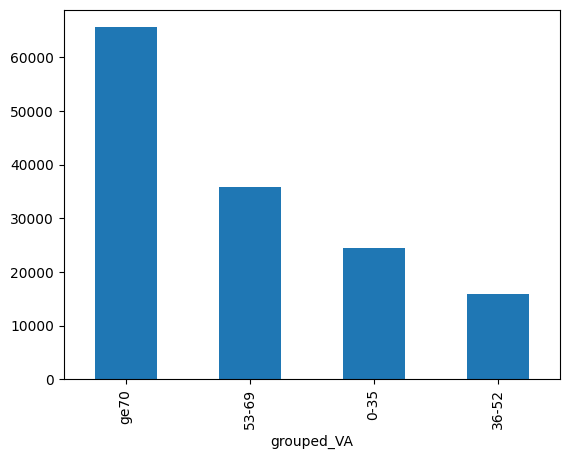

In [ ]:
df = df.dropna(subset=["grouped_VA"])
print(df["grouped_VA"].value_counts(normalize=True))
df["grouped_VA"].value_counts().plot(kind="bar")

In [ ]:
bio = ["Neurosensory","RPE","IRF","SRF","SHRM","Drusenoid_PED","Serous_PED","Fibrovascular_PED"]
print(df[bio].isnull().sum())
print(df.shape)
print(df["grouped_age"].isnull().sum(), df["Gender"].isnull().sum())

NameError: name 'df' is not defined

In [ ]:
import pandas as pd

df = pd.read_csv("AMD_longitudinal_MEH_v4.csv")
df = df.dropna(subset=["grouped_VA"])      # keep only labeled rows

bio = ["Neurosensory","RPE","IRF","SRF","SHRM","Drusenoid_PED","Serous_PED","Fibrovascular_PED"]
print(df[bio].isnull().sum())
print(df.shape)
print(df["grouped_age"].isnull().sum(), df["Gender"].isnull().sum())

Neurosensory         26409
RPE                  26409
IRF                  26409
SRF                  26409
SHRM                 26409
Drusenoid_PED        26409
Serous_PED           26409
Fibrovascular_PED    26409
dtype: int64
(141741, 16)
10 0


In [ ]:
before = df["grouped_VA"].value_counts(normalize=True)
df = df.dropna(subset=bio + ["grouped_age"])
after = df["grouped_VA"].value_counts(normalize=True)

print(df.shape)
print(pd.concat([before, after], axis=1, keys=["before","after"]))
print(df["ID"].nunique())

(115332, 16)
              before     after
grouped_VA                    
ge70        0.462350  0.470901
53-69       0.252651  0.259555
0-35        0.173175  0.153427
36-52       0.111824  0.116117
3212


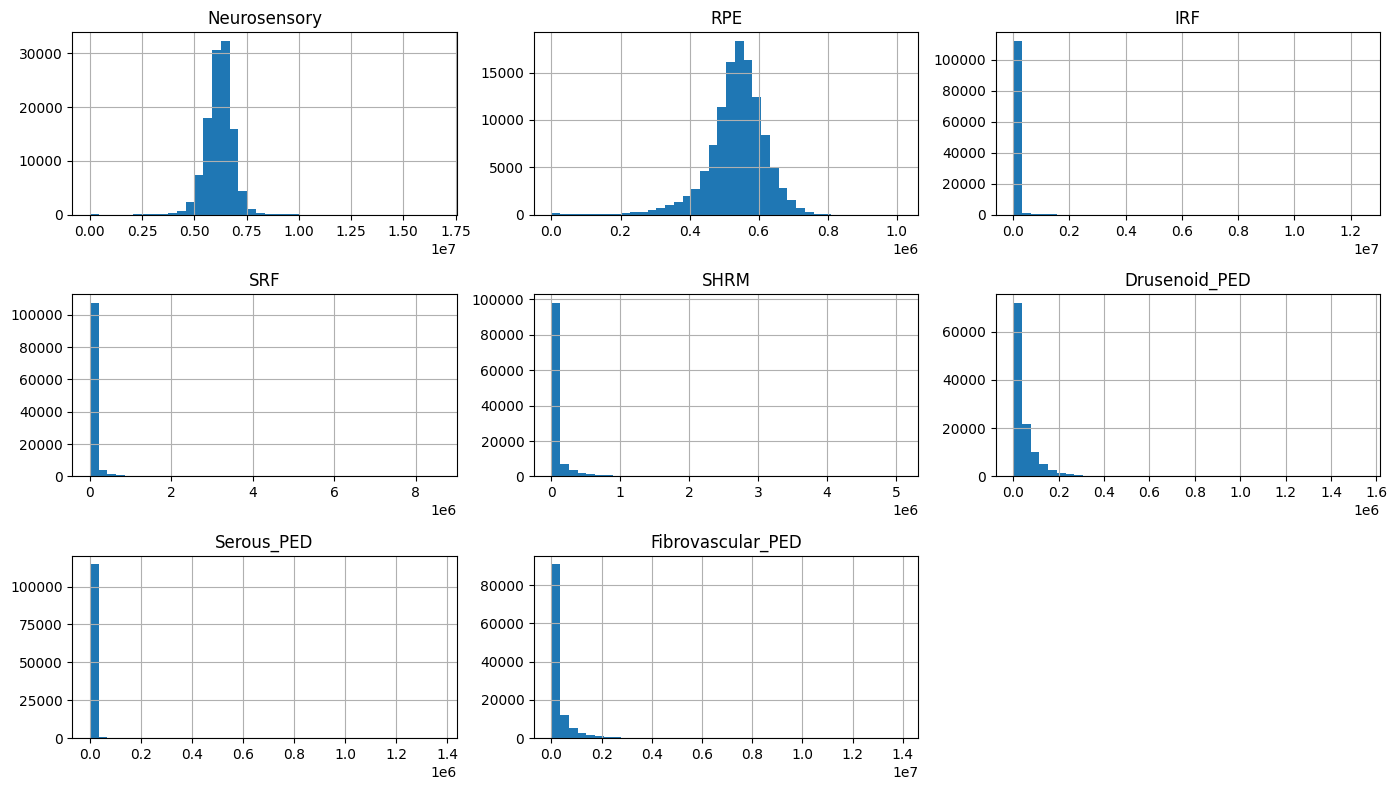

            Neurosensory       RPE     IRF     SRF      SHRM  Drusenoid_PED  \
grouped_VA                                                                    
0-35           5951092.4  489183.6  2830.4  2613.2  135548.4        17508.4   
36-52          6058263.4  516761.2   534.0   909.2   27111.6        25356.0   
53-69          6156246.4  536058.4   130.4   704.4    4525.6        29938.0   
ge70           6367158.6  567809.0    25.2   138.8     254.0        24273.6   

            Serous_PED  Fibrovascular_PED  
grouped_VA                                 
0-35               0.0           339978.8  
36-52              0.0           128482.2  
53-69              0.0            72150.0  
ge70               0.0            15299.4  


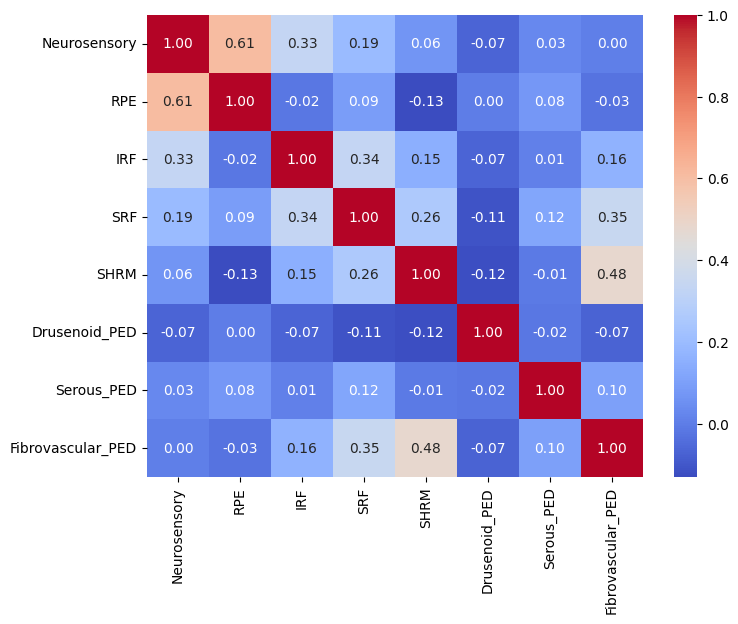

grouped_VA  0-35  36-52  53-69  ge70
Gender                              
Female      0.15   0.11   0.27  0.47
Male        0.15   0.12   0.25  0.48
grouped_VA   0-35  36-52  53-69  ge70
grouped_age                          
50-59        0.07   0.12   0.14  0.67
60-69        0.08   0.08   0.20  0.64
70-79        0.12   0.10   0.24  0.54
ge80         0.19   0.13   0.29  0.39
grouped_VA         0-35  36-52  53-69  ge70
grouped_ethnicity                          
Asian              0.18   0.12   0.28  0.42
Black              0.14   0.11   0.23  0.52
Other or unknown   0.16   0.12   0.27  0.45
White              0.15   0.11   0.25  0.49
grouped_VA  0-35  36-52  53-69  ge70
Eye                                 
Left        0.16   0.12   0.25  0.47
Right       0.14   0.12   0.26  0.47


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. biomarker distributions
df[bio].hist(bins=40, figsize=(14,8))
plt.tight_layout(); plt.show()

# 2. biomarkers by class (medians)
print(df.groupby("grouped_VA")[bio].median())

# 3. correlation between biomarkers
plt.figure(figsize=(8,6))
sns.heatmap(df[bio].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

# 4. categorical features vs class
for c in ["Gender","grouped_age","grouped_ethnicity","Eye"]:
    print(pd.crosstab(df[c], df["grouped_VA"], normalize="index").round(2))

In [ ]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# --- load and clean ---
df = pd.read_csv("AMD_longitudinal_MEH_v4.csv")
bio = ["Neurosensory","RPE","IRF","SRF","SHRM","Drusenoid_PED","Serous_PED","Fibrovascular_PED"]
df = df.dropna(subset=["grouped_VA"] + bio + ["grouped_age"])

# --- split by ID ---
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df, df["grouped_VA"], groups=df["ID"]))
train = df.iloc[train_idx]
test  = df.iloc[test_idx]

print(df.shape, train.shape, test.shape)
print("ID overlap:", set(train["ID"]) & set(test["ID"]))   # must be empty
print(train["grouped_VA"].value_counts(normalize=True).round(3))
print(test["grouped_VA"].value_counts(normalize=True).round(3))

train.to_csv("Train.csv", index=False)
test.to_csv("test.csv", index=False)

(115332, 16) (92590, 16) (22742, 16)
ID overlap: set()
grouped_VA
ge70     0.478
53-69    0.256
0-35     0.149
36-52    0.117
Name: proportion, dtype: float64
grouped_VA
ge70     0.442
53-69    0.275
0-35     0.171
36-52    0.112
Name: proportion, dtype: float64


In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

skewed = ["IRF","SRF","SHRM","Drusenoid_PED","Serous_PED","Fibrovascular_PED"]
normal = ["Neurosensory","RPE"]
age_order = [["50-59","60-69","70-79","ge80"]]

prep = ColumnTransformer([
    ("skew", Pipeline([("log", FunctionTransformer(np.log1p)),
                       ("sc", StandardScaler())]), skewed),
    ("norm", StandardScaler(), normal),
    ("age",  OrdinalEncoder(categories=age_order), ["grouped_age"]),
    ("eth",  OneHotEncoder(handle_unknown="ignore"), ["grouped_ethnicity"]),
])

features = skewed + normal + ["grouped_age","grouped_ethnicity"]
X_train, y_train = train[features], train["grouped_VA"]
X_test,  y_test  = test[features],  test["grouped_VA"]

X_train_p = prep.fit_transform(X_train)   # fit on train ONLY
X_test_p  = prep.transform(X_test)
print(X_train_p.shape, X_test_p.shape)

(92590, 13) (22742, 13)
